In [5]:
%env CUDA_DEVICE_ORDER=PCI_BUS_ID
%env CUDA_VISIBLE_DEVICES=0
%pylab inline
%load_ext autoreload
%autoreload 2

env: CUDA_DEVICE_ORDER=PCI_BUS_ID
env: CUDA_VISIBLE_DEVICES=0
%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import json
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
import os
from pathlib import Path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.pyplot as plt
import matplotlib as mpl
from openTSNE import TSNE
import colorcet as cc

In [ ]:
from ssl_neuron.datasets import GraphDataset
from ssl_neuron.utils import plot_neuron, knn_accuracy, save_trial_results
from ssl_neuron.graphdino import create_model

In [8]:
TRIAL = "trial9"

#### Load config

In [9]:
config = json.load(open(f'../configs/{TRIAL}.json'))

In [10]:
# Plotting for later maybe
# dset = GraphDataset(config, mode='all')
# feat, neigh, cell_id = dset.__getsingleitem__(0)
# plot_neuron(neigh, feat)

In [11]:
# plt.scatter(np.arange(config['model']['dim']), cell_meta['latents'].mean(axis=0))

# plt.errorbar(np.arange(config['model']['dim']), cell_meta['latents'].mean(axis=0), yerr = cell_meta['latents'].std(axis=0), fmt='none')

In [12]:
cell_meta = pd.read_csv(os.path.join(config['trainer']['latents_dir'], f'{TRIAL}.csv'))

In [13]:
# Load IDs
data_dir = config['data']['path']

train_ids = np.load(os.path.join(data_dir, 'train_ids.npy')).astype(str)
val_ids = np.load(os.path.join(data_dir, 'val_ids.npy')).astype(str)
test_ids = np.load(os.path.join(data_dir, 'test_ids.npy')).astype(str)

# Create mapping
split_map = {
    **dict.fromkeys(train_ids, 'train'),
    **dict.fromkeys(val_ids, 'val'),
    **dict.fromkeys(test_ids, 'test')
}

# Assign split to each cell
cell_meta['split'] = cell_meta['cell_id'].astype(str).map(split_map)

# Check results
print(cell_meta['split'].value_counts(dropna=False))

train    2680
test      575
val       575
Name: split, dtype: int64


In [14]:
cell_meta["latent"] = cell_meta["latent"].apply(
    lambda x: np.fromstring(x.strip("[]"), sep=" ")
    if isinstance(x, str) and x.strip()
    else np.array([])
)

In [15]:
def get_celltype_colors(cell_meta):
    celltypes = sorted(cell_meta['celltype_final'].dropna().unique())

    colors = cc.glasbey[:len(celltypes)]

    color_dict = dict(zip(celltypes, colors))

    return color_dict

color_dict = get_celltype_colors(cell_meta)

In [16]:
def plot_tsne(
    cell_meta,
    unknown_labels=True,
    color_by='celltype',
    perplexity=30,
    random=True,
    color_dict=None
):

    if unknown_labels:
        plot_df = cell_meta.copy()
    else:
        plot_df = cell_meta[cell_meta['celltype_final'].notna()].copy()

    X = np.stack(plot_df['latent'].values).astype(np.float32)

    print("Embedding shape:", X.shape)
    print("Embedding dtype:", X.dtype)

    # Run t-SNE
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        initialization='random',
        learning_rate=200.0,
        n_jobs=-1
    )

    X_tsne = np.array(tsne.fit(X))

    plot_df['TSNE1'] = X_tsne[:, 0]
    plot_df['TSNE2'] = X_tsne[:, 1]

    if random:
        plot_df = plot_df.sample(frac=1).reset_index(drop=True)

    fig, ax = plt.subplots(
        figsize=(8, 5) if color_by != 'celltype' else (12, 5)
    )

    # 1. Color by cell type
    if color_by == 'celltype':

        if color_dict is None:
            color_dict = get_celltype_colors(plot_df)

        point_colors = plot_df['celltype_final'].map(color_dict)

        if unknown_labels:
            point_colors = point_colors.fillna('lightgrey')

        ax.scatter(
            plot_df['TSNE1'],
            plot_df['TSNE2'],
            c=point_colors,
            s=15,
            alpha=0.8,
            zorder=2
        )

        from matplotlib.lines import Line2D

        legend_elements = [
            Line2D(
                [0], [0],
                marker='o',
                color='w',
                label=str(celltype),
                markerfacecolor=color,
                markersize=6
            )
            for celltype, color in color_dict.items()
        ]

        if unknown_labels:
            legend_elements.append(
                Line2D(
                    [0], [0],
                    marker='o',
                    color='w',
                    label='Unknown',
                    markerfacecolor='lightgrey',
                    markersize=6
                )
            )

        ax.legend(
            handles=legend_elements,
            title='Cell Type',
            bbox_to_anchor=(1.02, 1),
            loc='upper left',
            ncol=2,
            fontsize=8,
            markerscale=1.5
        )

    # 2. Color by a continuous variable
    elif color_by in plot_df.columns and color_by != 'none':

        values = plot_df[color_by].to_numpy(dtype=float)

        vmin, vmax = np.nanpercentile(values, [2, 98])
        vcenter = np.nanmean(values)

        norm = TwoSlopeNorm(
            vmin=vmin,
            vcenter=vcenter,
            vmax=vmax
        )

        cmap = mpl.colormaps['RdBu_r']

        if random:
            order = np.random.permutation(len(plot_df))
        else:
            order = np.arange(len(plot_df))

        sc = ax.scatter(
            plot_df['TSNE1'].to_numpy()[order],
            plot_df['TSNE2'].to_numpy()[order],
            c=values[order],
            cmap=cmap,
            norm=norm,
            s=15,
            alpha=0.8
        )

        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label(color_by)

    # 3. Single color
    elif color_by == 'none':

        ax.scatter(
            plot_df['TSNE1'],
            plot_df['TSNE2'],
            color='steelblue',
            s=15,
            alpha=0.7
        )

    else:
        raise ValueError(
            f"Unknown color_by='{color_by}'. "
            "Use 'celltype', 'none', or a numerical column name."
        )

    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.set_title(f't-SNE of Neuron Embeddings (colored by {color_by})')

    plt.tight_layout()
    plt.show()

    return plot_df

Embedding shape: (3225, 32)
Embedding dtype: float32


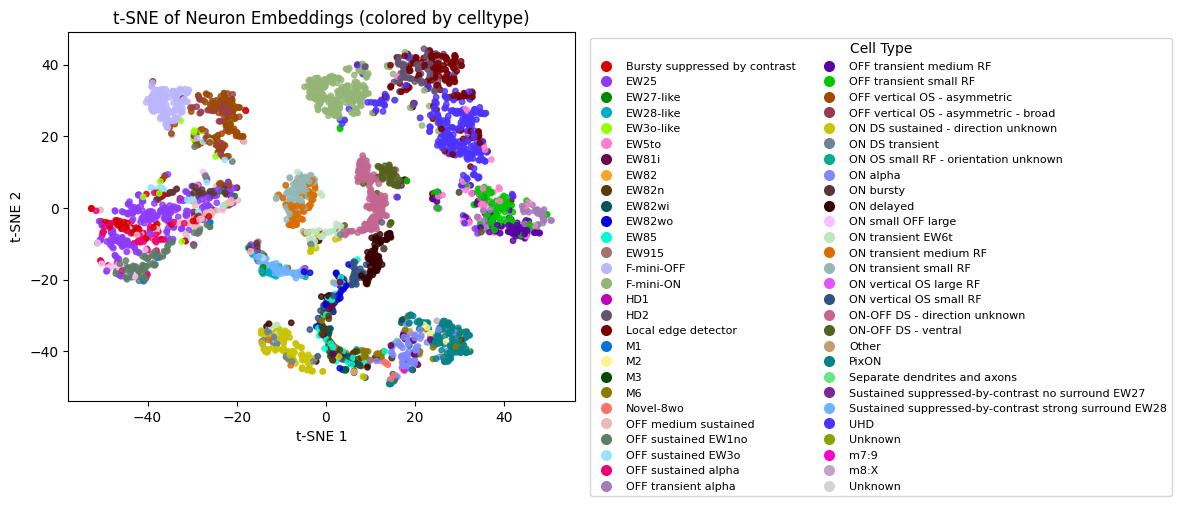

In [13]:
# plot_df = plot_tsne(cell_meta, unknown_labels=False, color_by='celltype')

plot_df = plot_tsne(cell_meta[cell_meta['split'].isin(['train', 'val'])], unknown_labels=True, color_dict=color_dict, color_by='celltype')

# plot_df = plot_tsne(cell_meta, color_by='none')

# plot_df = plot_tsne(cell_meta[cell_meta['split'] == 'train'], color_dict=color_dict, color_by='soma_z')


Training losses:
[6.81220245 6.59941626 5.65465879 4.21508646 2.98991632 2.29621434
 1.65035164 1.25463223 0.99109441 0.87293321 0.79600471 0.79362935
 0.77903688 0.77321237 0.76142347 0.7461825  0.73456138 0.70093983
 0.70670837 0.68504363 0.64107323 0.6373632  0.6369884  0.60563707
 0.57770628 0.57889497 0.5500071  0.55636889 0.52236915 0.53465289
 0.52531165 0.49084517 0.49402225 0.46846241 0.45740223 0.434466
 0.43869382 0.41912505 0.39767885 0.39322186 0.38634416 0.39658311
 0.38481435 0.36662221 0.35601026 0.37004861 0.35923114 0.3362515
 0.33515236 0.31669155 0.32952225 0.31021208 0.31300795 0.30368558
 0.28712559 0.29172528 0.28043664 0.27499968 0.27328047 0.27962074
 0.26658586 0.2675266  0.25870875 0.26366976 0.23895064 0.25154015
 0.25201836 0.23110826 0.23515528 0.23582995 0.23267794 0.22228339
 0.23638043 0.22957556 0.22087529 0.23206106 0.21576203 0.20631437
 0.21020809 0.2209453  0.21722218 0.20526348 0.19970964 0.20502667
 0.20203003 0.21010827 0.20291418 0.19256228 0.1

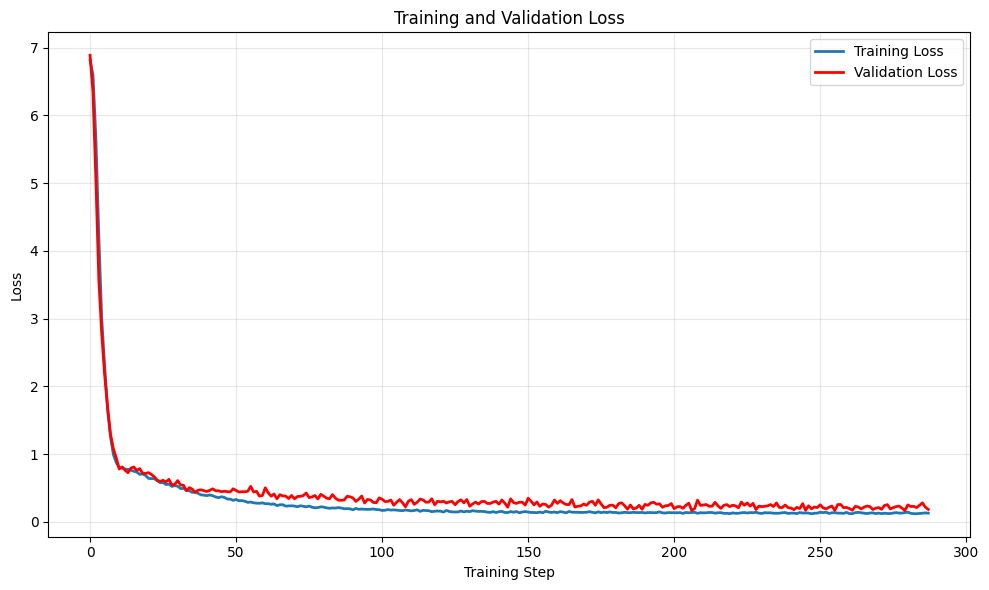

In [14]:
loss_dir = Path("..") / Path(config['trainer']['losses_dir']) / Path(TRIAL)

losses = np.load(loss_dir / "training_loss.npy")
val_losses = np.load(loss_dir / "val_loss.npy")

print("Training losses:")
print(losses)

print("\nValidation losses:")
print(val_losses)

print(f"\nNumber of training steps: {len(losses)}")
print(f"Initial training loss: {losses[0]:.6f}")
print(f"Final training loss: {losses[-1]:.6f}")
print(f"Minimum training loss: {np.min(losses):.6f}")

print(f"\nNumber of validation steps: {len(val_losses)}")
print(f"Initial validation loss: {val_losses[0]:.6f}")
print(f"Final validation loss: {val_losses[-1]:.6f}")
print(f"Minimum validation loss: {np.min(val_losses):.6f}")

plt.figure(figsize=(10, 6))

plt.plot(losses, label="Training Loss", linewidth=2)
plt.plot(val_losses, label="Validation Loss", color="red", linewidth=2)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## KNN accuracy

In [67]:
accuracy_train, results = knn_accuracy(
    cell_meta,
    splits=["train", "test", "val"],
    confidence=["High"],
    k = 5,
    print_val=True
)

Cells evaluated: 2050
Splits: ['train', 'test', 'val']
Confidence: ['High']
Cell types: All
k: 5
KNN accuracy: 0.8132 (81.32%)


In [69]:
accuracy_all, results = knn_accuracy(
    cell_meta,
    splits=["train", "test", "val"],
    confidence= ['High', "Low", "Medium"],
    k = 5,
    print_val=True
)

Cells evaluated: 3318
Splits: ['train', 'test', 'val']
Confidence: ['High', 'Low', 'Medium']
Cell types: All
k: 5
KNN accuracy: 0.7559 (75.59%)


In [70]:
accuracy, results = knn_accuracy(
    cell_meta,
    splits=["test"],
    confidence=["High"],
    k = 5,
    print_val=True
)

Cells evaluated: 559
Splits: ['test']
Confidence: ['High']
Cell types: All
k: 5
KNN accuracy: 0.7227 (72.27%)


## Save results

In [56]:
trial_results = save_trial_results(
    cell_meta=cell_meta,
    config=config,
    TRIAL=TRIAL,
    k=5
)


Results saved to /gpfs01/berens/user/pgivehchian/ssl_neuron/outputs/results.csv


# Data Analysis

### z means

Embedding shape: (3225, 32)
Embedding dtype: float32


ValueError: Unknown color_by='z_mean'. Use 'celltype', 'none', or a numerical column name.

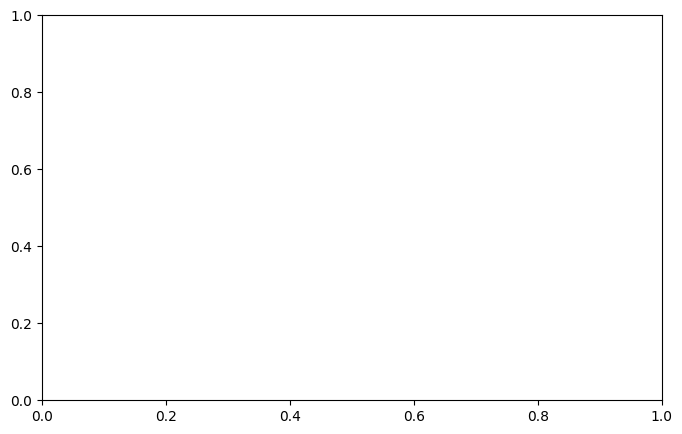

In [15]:
plot_df = plot_tsne(cell_meta[cell_meta['split'].isin(['train', 'val'])], unknown_labels=True, color_by='z_mean')

In [ ]:
plot_df = plot_tsne(cell_meta, unknown_labels=True, color_by='n_nodes_raw')

ValueError: all input arrays must have the same shape

In [ ]:
overlapping_types = [
    "OFF sustained EW1no",
    "OFF sustained alpha",
    "OFF sustained EW3o",
    "ON bursty",
    "Bursty suppressed by contrast"
]